In [1]:
%matplotlib inline 

In [35]:
import os
import io
import re
import pandas as pd
import json

In [36]:
#work_fldr = r'D:\Users\Work\OneDrive - Transport Systems Catapult\Research\PhD\Models\tripchains_from_od'
#work_fldr = r'C:\Users\haris.ballis\OneDrive - Transport Systems Catapult\Research\PhD\Programming\tcs_od'
#work_fldr = r'C:\Users\Work\Desktop\local_optimisation\tripchains_from_od'
#work_fldr = r'/mnt/sda1/Users/Linux/OneDrive/PhD/Models/tcs_od'
#work_fldr = r'C:\Users\haris.ballis\Desktop\local_cplex_run\tcs_od'
work_fldr = r'../'

In [37]:
data_source = 'mnd_TSC'
model_name = 'lsoa'
trips_direction = 'sample_perc_01'
distr_contr_enabled_switch = [True]

tolerance = 0.01
out_folder = os.path.join(work_fldr, r'generation/outputs', r'{}/{}/{}'.format(data_source, model_name, trips_direction))

In [38]:
def prepare_results_filepaths(flpaths, run_results_fldr):

    flpaths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    flpaths['tours_mdl_descr'] = os.path.join(run_results_fldr, 'tours_mdl_descr.csv')
    flpaths['tours_mdl_info'] = os.path.join(run_results_fldr, 'tours_mdl_info.csv')
    flpaths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    flpaths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')

    return flpaths

In [39]:
def get_optimisation_results(infilepath):
    with open(infilepath) as f:
        data = json.load(f)

        results = data['Solution'][1]['Variable']

        df_data = list()
        for chain, val in results.items():
            cid = re.search('\[(\d+)\]', chain, re.DOTALL).group(1)
            times_used = val['Value']
            df_data.append([int(cid), times_used])

        df = pd.DataFrame(df_data, columns=['TripChainId', 'TimesUsed']).set_index('TripChainId').squeeze()
        return df

In [40]:
def convert_optimisation_output_to_trips(tcs_descr, optim_output):
    # Calculate how many times the tripchain has been used by the optimiser 
    df = tcs_descr.join(optim_output, how='right')
    grpby_cols = ['OrigZoneId', 'DestZoneId', 'Purpose', 'TimePeriod']
    optimisation_trips = df.groupby(grpby_cols)['TimesUsed'].sum().squeeze()
    optimisation_trips.name = 'OptimisationTrips'
    return optimisation_trips


In [41]:
def get_modelled_trips(paths):
    
    tcs_descr = pd.read_csv(paths['tours_mdl_descr'], index_col=['TripChainId'])
    optim_output = get_optimisation_results(paths['optimisation_results'])
    
    if optim_output is not None:
        optimisation_trips = convert_optimisation_output_to_trips(tcs_descr, optim_output)
        return optimisation_trips, optim_output
    else:
        return None

In [42]:
def include_run_info(df, legs, trips_thresh, distr_constr_enabled):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    df['MaxLegs'] = int(legs)
    df['TripsThresh'] = int(trips_thresh)
    df['DistrConstr'] = distr_constr_enabled
    df.set_index(['MaxLegs', 'TripsThresh', 'DistrConstr'], append=True, inplace=True)
    df = df.squeeze()
    
    return df

In [43]:
def prepare_ods_comparison(optim_ods, init_ods):
    comp = init_ods.to_frame().join(optim_ods)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [44]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [45]:
def prepare_ditribution_comparison(fldrpaths):
    tcs_info = pd.read_csv(fldrpaths['tours_mdl_info'], index_col=['TripChainId'])
    optim_output = get_optimisation_results(fldrpaths['optimisation_results'])
    observed_distr = pd.read_csv(fldrpaths['observed_distribution'], index_col='DistrGroupId')
    observed_distr.drop(columns=['Size'], inplace=True)

    df = tcs_info.join(optim_output, how='right')
    optim_distr = df.groupby('DistrGroupId')['TimesUsed'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in observed_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    observed_distr.set_index(idx_cols, append=True, inplace=True)
    observed_distr = observed_distr.squeeze()
    
    distr_comp = observed_distr.to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['Observed', 'Estimated']
    distr_comp.columns.name = 'Source'
    distr_comp = distr_comp.stack()
    distr_comp.name = 'Percentage'

    return distr_comp

In [46]:
def collapse_tour_legs(tours, leg_descr_cols):
    seqs = list()
    for c in leg_descr_cols:
        seq = tours.groupby('TripChainId')[c].apply(tuple)
        seqs.append(seq)
    
    tours_collapsed = pd.concat(seqs, axis=1)
    
    return tours_collapsed

In [47]:
def prepare_descr_comparison(flpaths, mdl_nchains):
    tours_obs = pd.read_csv(flpaths['tours_obs_descr'], index_col=[0, 1])
    tours_mdl = pd.read_csv(flpaths['tours_mdl_descr'], index_col=[0, 1])

    # Standardising frames
    cmn_idx_names = ['TripChainId', 'LegSeqIdx']
    tours_obs.index.names = cmn_idx_names
    tours_mdl.index.names = cmn_idx_names

    # Kepp only the used tripchains
    tours_mdl_used = tours_mdl.loc[mdl_nchains.index]
    
    # Split Purpose in purpose and direction
    tours_mdl_used['Purpose'], tours_mdl_used['Direction'] = tours_mdl_used['Purpose'].str.split('_', 1).str

    leg_descr_cols = ['OrigZoneId', 'DestZoneId', 'Purpose', 'Direction', 'TimePeriod']

    tours_obs_clpsd = collapse_tour_legs(tours_obs, leg_descr_cols)
    tours_mdl_clpsd = collapse_tour_legs(tours_mdl_used, leg_descr_cols)
    
    comp = pd.merge(left=tours_obs_clpsd.reset_index(), right=tours_mdl_clpsd.reset_index(),
                    on=leg_descr_cols, how='outer', suffixes=('_obs', '_mdl'),
                    indicator='Exist')
    
    comp.drop(columns=leg_descr_cols, inplace=True)
    comp = comp.squeeze()

    comp['Exist'] = comp['Exist'].str.replace('left_only', 'obs_only')
    comp['Exist'] = comp['Exist'].str.replace('right_only', 'mdl_only')

    return comp, tours_mdl_used

In [48]:
##### MAIN
generation_inputs_fldr = os.path.join(work_fldr,
                                      r'generation/inputs/{}/{}/{}'.format(data_source, model_name, trips_direction))
inputs = get_input_params_from_folder(out_folder)

concat_mdl_ods = list()
concat_obs_ods = list()

concat_tours_mdl_nchains = list()
concat_tours_mdl_used_descr = list()

concat_comp_distrs = list()
concat_comp_descrs = list()

flpaths = dict()
flpaths['tours_obs_descr'] = os.path.join(generation_inputs_fldr, 'obs_tours_descr.csv')
flpaths['tours_obs_info'] = os.path.join(generation_inputs_fldr, 'obs_tours_info.csv')
tours_obs = pd.read_csv(flpaths['tours_obs_descr'], index_col=[0, 1])

for legs, trips_thresh, distr_constr_enabled in inputs:
    
    print(model_name)
    print(legs, trips_thresh, distr_constr_enabled)
    
    run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
    run_results_fldr = os.path.join(out_folder, run_tmplt)
    
    flpaths = prepare_results_filepaths(flpaths, run_results_fldr)
    
    mdl_od, mdl_nchains = get_modelled_trips(flpaths)
    
    if mdl_od is None:
        print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
        continue
    
    comp_distr = prepare_ditribution_comparison(flpaths)
    comp_descr, tours_mdl_used_descr = prepare_descr_comparison(flpaths, mdl_nchains)
    
    idx_cols_od = ['OrigZoneId', 'DestZoneId', 'Purpose', 'TimePeriod']
    obs_od = pd.read_csv(flpaths['od'], index_col=idx_cols_od)
    obs_od.drop(columns=['LegId'], inplace=True)
    
    obs_od = include_run_info(obs_od, legs, trips_thresh, distr_constr_enabled)
    mdl_od = include_run_info(mdl_od, legs, trips_thresh, distr_constr_enabled)
    mdl_nchains = include_run_info(mdl_nchains, legs, trips_thresh, distr_constr_enabled)
    tours_mdl_used_descr = include_run_info(tours_mdl_used_descr, legs, trips_thresh, distr_constr_enabled)
    comp_distr = include_run_info(comp_distr, legs, trips_thresh, distr_constr_enabled)
    comp_descr = include_run_info(comp_descr, legs, trips_thresh, distr_constr_enabled)
    
    concat_mdl_ods.append(mdl_od)
    concat_obs_ods.append(obs_od)
    concat_tours_mdl_nchains.append(mdl_nchains)
    concat_tours_mdl_used_descr.append(tours_mdl_used_descr)
    concat_comp_descrs.append(comp_descr)
    concat_comp_distrs.append(comp_distr)
    
mdl_nchains = pd.concat(concat_tours_mdl_nchains)

ods_mdl = pd.concat(concat_mdl_ods)
ods_obs = pd.concat(concat_obs_ods)

tours_mdl_used_descr = pd.concat(concat_tours_mdl_used_descr)

comp_ods = prepare_ods_comparison(ods_mdl, ods_obs)
comp_distrs = pd.concat(concat_comp_distrs)
comp_descrs = pd.concat(concat_comp_descrs)


lsoa
5 1 True


/home/harisbal/anaconda3/envs/phd/lib/python3.6/site-packages/ipykernel_launcher.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  


In [49]:
export = False
if export:
    mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
    comp_distrs.to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
    comp_ods.to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
    comp_descrs.to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)

In [50]:
df = comp_distrs.copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Source')
df['Diff_perc'] = df.Observed.sub(df.Estimated)

df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df.dropna(inplace=True)
df['BelowTolerance'].all()

True

In [51]:
df = comp_ods.groupby(level=['MaxLegs', 'TripsThresh', 'DistrConstr', 'TripsSource', 'Purpose']).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.DailyTrips - df.OptimisationTrips
df['Diff_perc'] = df.OptimisationTrips/df.DailyTrips - 1

df.style.format({
    'OptimisationTrips': '{:,.0f}'.format,
    'DailyTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [52]:
mdl_nchains.groupby(level=[1,2,3]).sum()

MaxLegs  TripsThresh  DistrConstr
5        1            True           290.0
Name: TimesUsed, dtype: float64

(5, 1, True)


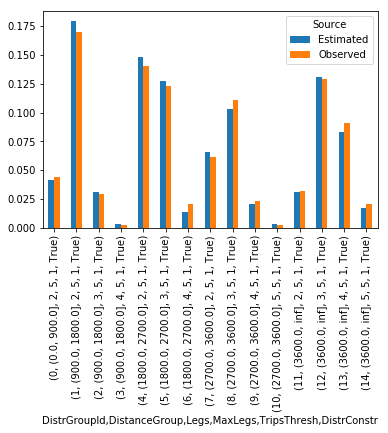

In [53]:
dfg = comp_distrs.groupby(level=['MaxLegs', 'TripsThresh', 'DistrConstr'])
for k, g in dfg:
    print(k)
    plt = g.unstack('Source')
    plt.plot(kind='bar')

In [54]:
comp_descrs.groupby(['MaxLegs', 'TripsThresh', 'DistrConstr', 'Exist']).size().unstack('DistrConstr')

DistrConstr                   True
MaxLegs TripsThresh Exist         
5       1           both       288
                    mdl_only     2
                    obs_only    54

In [55]:
tours_mdl_used_descr

Purpose TimePeriod  \
TripChainId LegSeqIdx MaxLegs TripsThresh DistrConstr                      
1           0         5       1           True             HB         OP   
            1         5       1           True             HB         OP   
2           0         5       1           True             HB         IP   
            1         5       1           True             HB         OP   
3           0         5       1           True             HB         PM   
            1         5       1           True             HB         PM   
4           0         5       1           True             HB         AM   
            1         5       1           True            NHB         IP   
            2         5       1           True             HB         PM   
5           0         5       1           True             HB         AM   
            1         5       1           True             HB         AM   
6           0         5       1           True             HB         IP   
            1         5       1           True            NHB         IP   
            2         5       1           True             HB         PM   
7           0         5       1           True             HB         IP   
            1         5       1           True             HB         IP   
8           0         5       1           True             HB         IP   
            1         5       1           True            NHB         IP   
            2         5       1           True             HB         IP   
9           0         5       1           True             HB         AM   
            1         5       1           True            NHB         IP   
            2         5       1           True             HB         OP   
10          0         5       1           True             HB         IP   
            1         5       1           True             HB         OP   
11          0         5       1           True             HB         IP   
            1         5       1           True            NHB         IP   
            2         5       1           True             HB         PM   
12          0         5       1           True             HB         AM   
            1         5       1           True            NHB         PM   
            2         5       1           True            NHB         PM   
...                                                       ...        ...   
309         2         5       1           True            NHB         PM   
            3         5       1           True             HB         PM   
310         0         5       1           True             HB         IP   
            1         5       1           True             HB         PM   
311         0         5       1           True             HB         IP   
            1         5       1           True             HB         IP   
312         0         5       1           True             HB         IP   
            1         5       1           True             HB         IP   
313         0         5       1           True             HB         AM   
            1         5       1           True             HB         PM   
314         0         5       1           True             HB         IP   
            1         5       1           True            NHB         IP   
            2         5       1           True            NHB         PM   
            3         5       1           True             HB         OP   
315         0         5       1           True             HB         AM   
            1         5       1           True            NHB         IP   
            2         5       1           True             HB         PM   
316         0         5       1           True             HB         PM   
            1         5       1           True            NHB         OP   
            2         5       1           True             HB         OP   
317         0         5   

In [56]:
comp_descrs

,,,,TripChainId_obs,TripChainId_mdl,Exist
,MaxLegs,TripsThresh,DistrConstr,,,
0,5,1,True,286.0,129.0,both
1,5,1,True,1018.0,26.0,both
2,5,1,True,4380.0,240.0,both
3,5,1,True,5033.0,135.0,both
4,5,1,True,6570.0,NaN,obs_only
5,5,1,True,9208.0,153.0,both
6,5,1,True,10338.0,85.0,both
7,5,1,True,12544.0,25.0,both
8,5,1,True,12744.0,60.0,both


In [57]:
tours_obs.head()

OrigZoneId DestZoneId TimePeriod  IsFirstLeg  IsLastLeg  \
TourId LegSeqIdx                                                           
286    0          E01014510  E01032514         PM        True      False   
       1          E01032514  E01033344         OP       False      False   
       2          E01033344  E01014510         OP       False       True   
1018   0          E01014459  E01014713         AM        True      False   
       1          E01014713  E01014459         PM       False       True   

                 Purpose     Direction  TravelTime_s  
TourId LegSeqIdx                                      
286    0              HB      FromHome        1173.7  
       1             NHB  NonHomeBased         760.8  
       2              HB        ToHome         709.4  
1018   0              HB      FromHome        2200.9  
       1              HB        ToHome        2024.7

In [58]:
tours_obs.head().groupby(level=0).apply(lambda x: tuple(x))

TourId
286     (OrigZoneId, DestZoneId, TimePeriod, IsFirstLe...
1018    (OrigZoneId, DestZoneId, TimePeriod, IsFirstLe...
dtype: object

In [59]:
tours_obs.columns

Index(['OrigZoneId', 'DestZoneId', 'TimePeriod', 'IsFirstLeg', 'IsLastLeg',
       'Purpose', 'Direction', 'TravelTime_s'],
      dtype='object')

In [60]:
tours_obs.groupby(level=0).size().value_counts()

2    153
3    134
4     47
5      8
dtype: int64

In [61]:
leg_descr_cols = ['OrigZoneId', 'DestZoneId', 'TimePeriod', 'Purpose', 'Direction']
seqs = list()
for c in leg_descr_cols:
    seq = tours_obs.groupby('TourId')[c].apply(tuple)
    seqs.append(seq)

tmp = pd.concat(seqs, axis=1)

In [62]:
l = tmp.groupby(leg_descr_cols).size()
l[l>1]

Series([], dtype: int64)

In [87]:
tours_obs = pd.read_csv(flpaths['tours_obs_descr'], index_col=[0, 1])
tours_mdl = pd.read_csv(flpaths['tours_mdl_descr'], index_col=[0, 1])

# Standardising frames
cmn_idx_names = ['TripChainId', 'LegSeqIdx']
tours_obs.index.names = cmn_idx_names
tours_mdl.index.names = cmn_idx_names

# Kepp only the used tripchains
#tours_mdl_used = tours_mdl.loc[mdl_nchains.index]

tours_mdl_used = tours_mdl.copy()
# Split Purpose in purpose and direction
tours_mdl_used['Purpose'], tours_mdl_used['Direction'] = tours_mdl_used['Purpose'].str.split('_', 1).str

leg_descr_cols = ['OrigZoneId', 'DestZoneId', 'Purpose', 'Direction', 'TimePeriod']

tours_obs_clpsd = collapse_tour_legs(tours_obs, leg_descr_cols)
tours_mdl_clpsd = collapse_tour_legs(tours_mdl_used, leg_descr_cols)

comp = pd.merge(left=tours_obs_clpsd.reset_index(), right=tours_mdl_clpsd.reset_index(),
                on=leg_descr_cols, how='outer', suffixes=('_obs', '_mdl'),
                indicator='Exist')

comp.drop(columns=leg_descr_cols, inplace=True)
comp = comp.squeeze()

comp['Exist'] = comp['Exist'].str.replace('left_only', 'obs_only')
comp['Exist'] = comp['Exist'].str.replace('right_only', 'mdl_only')


In [88]:
idx = comp[comp.Exist=='obs_only'].TripChainId_obs

In [89]:
tours_obs_clpsd.loc[idx]

,OrigZoneId,DestZoneId,Purpose,Direction,TimePeriod
TripChainId,,,,,
6570.0,"(E01014747, E01033344, E01014504)","(E01033344, E01014504, E01014747)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(OP, PM, PM)"
37948.0,"(E01014920, E01014608, E01014526)","(E01014608, E01014526, E01014920)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(OP, OP, IP)"
49267.0,"(E01014717, E01014908, E01014981)","(E01014908, E01014981, E01014717)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(OP, IP, PM)"
83412.0,"(E01014843, E01014385, E01014622)","(E01014385, E01014622, E01014843)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(OP, PM, OP)"
98572.0,"(E01014675, E01014688, E01033331, E01014653)","(E01014688, E01033331, E01014653, E01014675)","(HB, NHB, NHB, HB)","(FromHome, NonHomeBased, NonHomeBased, ToHome)","(OP, AM, IP, IP)"
99437.0,"(E01014528, E01014868, E01033345, E01014637)","(E01014868, E01033345, E01014637, E01014528)","(HB, NHB, NHB, HB)","(FromHome, NonHomeBased, NonHomeBased, ToHome)","(OP, AM, IP, OP)"
111120.0,"(E01014999, E01014698, E01014392, E01014969)","(E01014698, E01014392, E01014969, E01014999)","(HB, NHB, NHB, HB)","(FromHome, NonHomeBased, NonHomeBased, ToHome)","(OP, PM, OP, OP)"
125914.0,"(E01014536, E01014994)","(E01014994, E01014536)","(HB, HB)","(FromHome, ToHome)","(OP, PM)"
140574.0,"(E01014974, E01033344, E01014871)","(E01033344, E01014871, E01014974)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(OP, IP, OP)"


In [78]:
comp[comp.Exist=='obs_only']

,TripChainId_obs,TripChainId_mdl,Exist
4,6570.0,NaN,obs_only
20,37948.0,NaN,obs_only
24,49267.0,NaN,obs_only
51,83412.0,NaN,obs_only
58,98572.0,NaN,obs_only
59,99437.0,NaN,obs_only
66,111120.0,NaN,obs_only
74,125914.0,NaN,obs_only
86,140574.0,NaN,obs_only
89,145958.0,NaN,obs_only


In [74]:
idx

Int64Index([  4,  20,  24,  51,  58,  59,  66,  74,  86,  89,  91,  92,  98,
            109, 120, 122, 130, 142, 144, 150, 160, 163, 171, 175, 209, 213,
            221, 223, 224, 226, 228, 229, 249, 252, 254, 255, 261, 266, 277,
            310, 312, 313, 314, 318, 323, 327, 330, 337],
           dtype='int64')

In [32]:
tours_obs_clpsd

,OrigZoneId,DestZoneId,Purpose,Direction,TimePeriod
TripChainId,,,,,
286,"(E01014510, E01032514, E01033344)","(E01032514, E01033344, E01014510)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(PM, OP, OP)"
1018,"(E01014459, E01014713)","(E01014713, E01014459)","(HB, HB)","(FromHome, ToHome)","(AM, PM)"
4380,"(E01032670, E01014646, E01015005, E01014669)","(E01014646, E01015005, E01014669, E01032670)","(HB, NHB, NHB, HB)","(FromHome, NonHomeBased, NonHomeBased, ToHome)","(IP, PM, PM, OP)"
5033,"(E01014592, E01015014)","(E01015014, E01014592)","(HB, HB)","(FromHome, ToHome)","(IP, IP)"
6570,"(E01014747, E01033344, E01014504)","(E01033344, E01014504, E01014747)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(OP, PM, PM)"
9208,"(E01014590, E01014526, E01033355)","(E01014526, E01033355, E01014590)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(AM, IP, IP)"
10338,"(E01014630, E01014491)","(E01014491, E01014630)","(HB, HB)","(FromHome, ToHome)","(AM, PM)"
12544,"(E01014459, E01014849, E01014847)","(E01014849, E01014847, E01014459)","(HB, NHB, HB)","(FromHome, NonHomeBased, ToHome)","(IP, IP, IP)"
12744,"(E01014501, E01014427)","(E01014427, E01014501)","(HB, HB)","(FromHome, ToHome)","(PM, OP)"
